In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv('employee_attrition_train.csv')

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1029 entries, 0 to 1028
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       893 non-null    float64
 1   Attrition                 1029 non-null   object 
 2   BusinessTravel            1024 non-null   object 
 3   DailyRate                 1002 non-null   float64
 4   Department                1029 non-null   object 
 5   DistanceFromHome          934 non-null    float64
 6   Education                 1029 non-null   int64  
 7   EducationField            1029 non-null   object 
 8   EmployeeCount             1029 non-null   int64  
 9   EmployeeNumber            1029 non-null   int64  
 10  EnvironmentSatisfaction   1029 non-null   int64  
 11  Gender                    1029 non-null   object 
 12  HourlyRate                1029 non-null   int64  
 13  JobInvolvement            1029 non-null   int64  
 14  JobLevel

In [10]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

In [44]:
df['MonthlyIncome'].describe()

count     1029.000000
mean      6449.796890
std       4794.525367
min       1009.000000
25%       2814.000000
50%       4735.000000
75%       8446.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64

In [23]:
df['MonthlyIncome'].skew()

np.float64(1.3475796720340596)

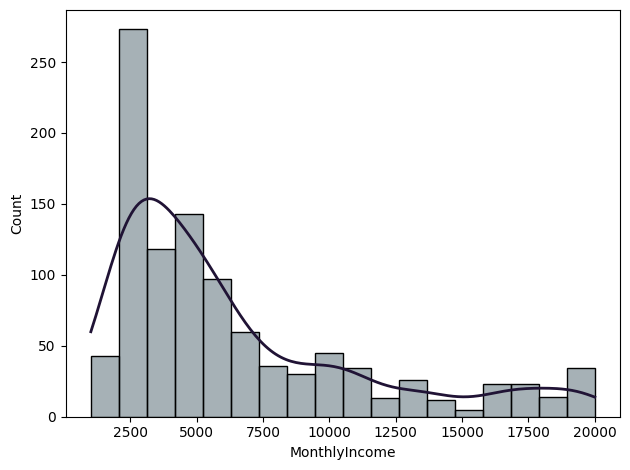

In [22]:
ax = sns.histplot(
    data=df,
    x="MonthlyIncome",
    color="#4f646f",
    kde=True
)
plt.tight_layout()

# Change only the KDE curve
ax.lines[-1].set_color("#201335")
ax.lines[-1].set_linewidth(2)

<Axes: xlabel='MonthlyIncome'>

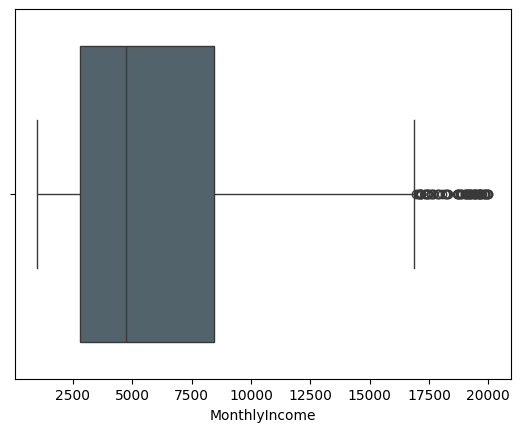

In [21]:
sns.boxplot(data=df,
    x="MonthlyIncome",
    color="#4f646f")

# Percentile Trimming

In [58]:
low = df['MonthlyIncome'].quantile(0.25)
low

np.float64(2814.0)

In [59]:
high = df['MonthlyIncome'].quantile(0.75)
high

np.float64(8446.0)

In [60]:
df[(df['MonthlyIncome'] < low) | (df['MonthlyIncome'] > high )].count().max()

514

In [61]:
1029 - 104

925

In [62]:
new_df = df[(df['MonthlyIncome'] > low) & (df['MonthlyIncome'] < high )]

In [63]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 513 entries, 1 to 1027
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       438 non-null    float64
 1   Attrition                 513 non-null    object 
 2   BusinessTravel            509 non-null    object 
 3   DailyRate                 500 non-null    float64
 4   Department                513 non-null    object 
 5   DistanceFromHome          464 non-null    float64
 6   Education                 513 non-null    int64  
 7   EducationField            513 non-null    object 
 8   EmployeeCount             513 non-null    int64  
 9   EmployeeNumber            513 non-null    int64  
 10  EnvironmentSatisfaction   513 non-null    int64  
 11  Gender                    513 non-null    object 
 12  HourlyRate                513 non-null    int64  
 13  JobInvolvement            513 non-null    int64  
 14  JobLevel      

<Axes: xlabel='MonthlyIncome'>

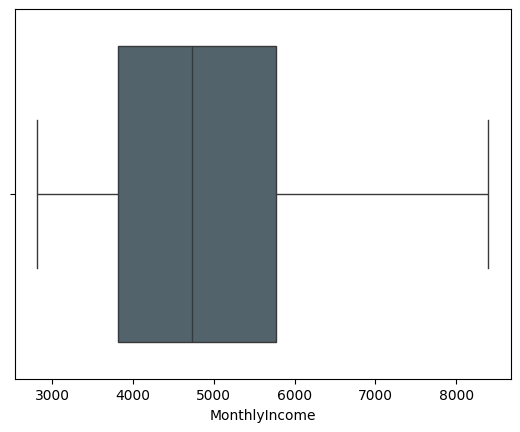

In [64]:
sns.boxplot(data=new_df,
    x="MonthlyIncome",
    color="#4f646f")

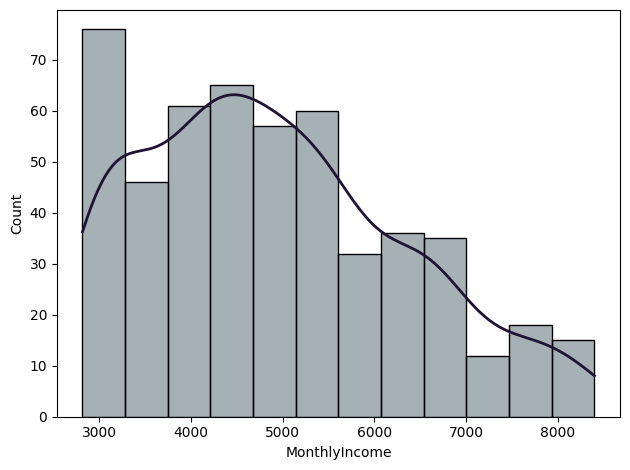

In [65]:
ax = sns.histplot(
    data=new_df,
    x="MonthlyIncome",
    color="#4f646f",
    kde=True
)
plt.tight_layout()

# Change only the KDE curve
ax.lines[-1].set_color("#201335")
ax.lines[-1].set_linewidth(2)

# Cappping

In [89]:
low = df['MonthlyIncome'].quantile(0.15)
low

np.float64(2424.0)

In [90]:
high = df['MonthlyIncome'].quantile(0.85)
high

np.float64(11088.599999999997)

In [91]:
df['new_MonthlyIncome'] = np.where((df['MonthlyIncome'] < low), low, 
                                   np.where((df['MonthlyIncome'] > high),high,
                                            df['MonthlyIncome']))
df.sample()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,new_MonthlyIncome
621,29.0,Yes,Travel_Rarely,992.0,Research & Development,1.0,3,Technical Degree,1,300,...,80,0,7,1,2,6,2,1,5,2424.0


<Axes: xlabel='new_MonthlyIncome'>

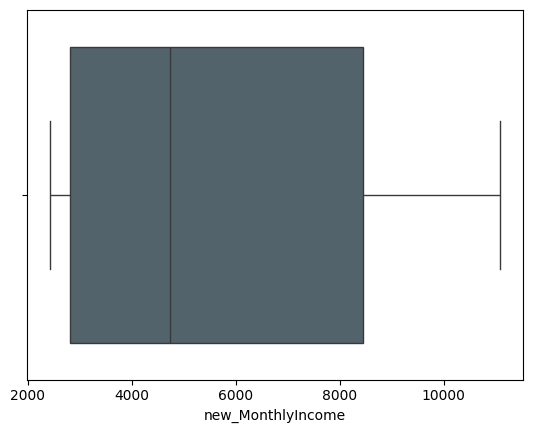

In [92]:
sns.boxplot(data=df,
    x="new_MonthlyIncome",
    color="#4f646f")

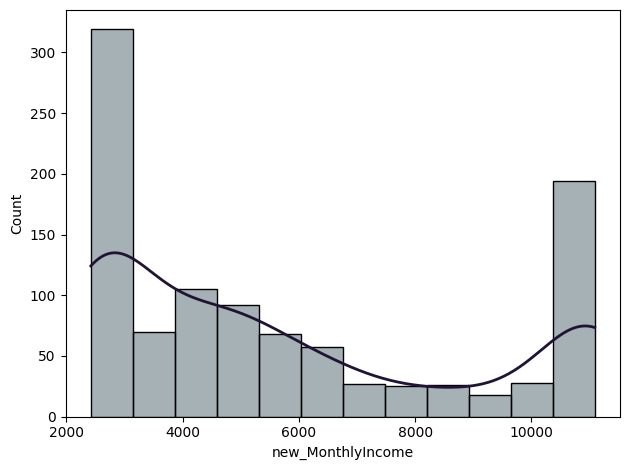

In [93]:
ax = sns.histplot(
    data=df,
    x="new_MonthlyIncome",
    color="#4f646f",
    kde=True
)
plt.tight_layout()

# Change only the KDE curve
ax.lines[-1].set_color("#201335")
ax.lines[-1].set_linewidth(2)